# Academic comparison of developmental-concern prediction models

This notebook consolidates the repository's **aggregate-only** evaluation evidence for the three independently modelled outcomes: Communication, Cognitive, and Social-emotional concern. It compares the original selected models, later individual candidates, classical hybrids, and TabICLv2-related experiments without treating any single metric as proof of overall superiority.

**Research boundary.** The notebook reads generated JSON reports only. It does not open participant-level datasets, fit models, adjust thresholds, write predictions, or expose identifiers. The overall concern decision is outside these tables because it is derived by OR of the three domain decisions rather than trained as a fourth model.

## Interpretation protocol

1. Development results and secondary-cohort results are presented separately.
2. PR-AUC is the primary ranking measure because positive outcomes are uncommon; higher is better.
3. ROC-AUC, balanced accuracy, sensitivity, specificity, precision and F1 are supporting measures; higher is better. Brier score assesses probabilistic error; lower is better.
4. A point estimate does not establish superiority. Paired uncertainty is shown where the stored report supports it.
5. Repeated-development intervals are descriptive because repeats share participants.
6. The reused 125-participant cohort provides secondary exploratory evidence, not fresh independent confirmation.
7. No clinical or diagnostic interpretation should be made from these research comparisons.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 180)
plt.style.use('seaborn-v0_8-whitegrid')

def repository_root():
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / 'reports' / 'generated').is_dir():
            return candidate
    raise FileNotFoundError('Run this notebook from the repository or its notebooks directory.')

ROOT = repository_root()
REPORTS = ROOT / 'reports' / 'generated'

def load_report(name):
    with (REPORTS / name).open(encoding='utf-8') as handle:
        return json.load(handle)

DOMAINS = {
    'target_communication_concern': 'Communication',
    'target_cognitive_concern': 'Cognitive',
    'target_social_emotional_concern': 'Social-emotional',
}
METRICS = ['average_precision_pr_auc', 'roc_auc', 'balanced_accuracy', 'sensitivity', 'specificity', 'precision', 'f1', 'brier_score']
DISPLAY_METRICS = {
    'average_precision_pr_auc': 'PR-AUC', 'roc_auc': 'ROC-AUC',
    'balanced_accuracy': 'Balanced accuracy', 'sensitivity': 'Sensitivity',
    'specificity': 'Specificity', 'precision': 'Precision', 'f1': 'F1',
    'brier_score': 'Brier score',
}
print(f'Aggregate report directory: {REPORTS}')

Aggregate report directory: F:\4thYear\2026July\Research_Component\reports\generated


## 1. Evidence and comparability audit

The audit below makes the evaluation stage explicit before numerical comparisons are shown. Models should only be directly ranked when their estimates arise from a sufficiently comparable evaluation design.

In [2]:
evidence = pd.DataFrame([
    ['Original five individual candidates', 'Development', 500, 'Repeated 5×5 participant-safe CV', 'Yes, within shared original folds', 'development-model-comparison-report.json'],
    ['CatBoost and EBM', 'Development', 500, 'Repeated 5×5 participant-safe nested CV', 'Shared with candidates in its report', 'development-additional-model-comparison-report.json'],
    ['LightGBM', 'Development', 500, 'Repeated 5×5 participant-safe nested CV', 'Numerically aligned; no paired uncertainty', 'development-lightgbm-comparison-report.json'],
    ['FIGS', 'Development', 500, 'Repeated 5×5 participant-safe nested CV', 'Numerically aligned; no paired uncertainty', 'development-figs-comparison-report.json'],
    ['HistGradientBoosting', 'Development', 500, 'Repeated 5×5 participant-safe nested CV', 'Numerically aligned; no paired uncertainty', 'development-histgradientboosting-comparison-report.json'],
    ['TabICLv2', 'Development', 500, 'Repeated 5×5 participant-safe nested CV', 'Numerically aligned; no paired uncertainty', 'development-tabiclv2-model-comparison-report.json'],
    ['Logistic–XGBoost hybrids', 'Development', 500, 'Repeated 5×5 participant-safe nested CV', 'Yes, within the hybrid experiment', 'development-hybrid-model-comparison-report.json'],
    ['Frozen selected models', 'Original locked test', 125, 'One-time frozen evaluation', 'Original confirmatory use', 'final-locked-test-report.json'],
    ['Equal Logistic–XGBoost hybrid', 'Secondary exploratory', 125, 'Reused previously evaluated cohort', 'Paired with original in report', 'secondary-exploratory-hybrid-evaluation-report.json'],
    ['TabICLv2', 'Secondary exploratory', 125, 'Reused previously evaluated cohort', 'Paired with original in report', 'secondary-tabiclv2-test-evaluation-report.json'],
], columns=['Evidence', 'Stage', 'Participants', 'Design', 'Comparison status', 'Source report'])
display(evidence)

,Evidence,Stage,Participants,Design,Comparison status,Source report
0,Original five individual candidates,Development,500,Repeated 5×5 participant-safe CV,"Yes, within shared original folds",development-model-comparison-report.json
1,CatBoost and EBM,Development,500,Repeated 5×5 participant-safe nested CV,Shared with candidates in its report,development-additional-model-comparison-report...
2,LightGBM,Development,500,Repeated 5×5 participant-safe nested CV,Numerically aligned; no paired uncertainty,development-lightgbm-comparison-report.json
3,FIGS,Development,500,Repeated 5×5 participant-safe nested CV,Numerically aligned; no paired uncertainty,development-figs-comparison-report.json
4,HistGradientBoosting,Development,500,Repeated 5×5 participant-safe nested CV,Numerically aligned; no paired uncertainty,development-histgradientboosting-comparison-re...
5,TabICLv2,Development,500,Repeated 5×5 participant-safe nested CV,Numerically aligned; no paired uncertainty,development-tabiclv2-model-comparison-report.json
6,Logistic–XGBoost hybrids,Development,500,Repeated 5×5 participant-safe nested CV,"Yes, within the hybrid experiment",development-hybrid-model-comparison-report.json
7,Frozen selected models,Original locked test,125,One-time frozen evaluation,Original confirmatory use,final-locked-test-report.json
8,Equal Logistic–XGBoost hybrid,Secondary exploratory,125,Reused previously evaluated cohort,Paired with original in report,secondary-exploratory-hybrid-evaluation-report...
9,TabICLv2,Secondary exploratory,125,Reused previously evaluated cohort,Paired with original in report,secondary-tabiclv2-test-evaluation-report.json


## 2. Development comparison of individual model families

This table includes all eleven individual families represented by completed aggregate reports: Logistic Regression, RBF SVM, Random Forest, Extra Trees, XGBoost, CatBoost, EBM, LightGBM, FIGS, HistGradientBoosting and TabICLv2. Values are participant-averaged out-of-fold metrics where available, or the corresponding mean repeated-validation summary for the isolated later candidates.

In [3]:
NAME = {
    'logistic_l2_balanced': 'Logistic Regression',
    'svm_rbf_balanced': 'RBF SVM',
    'random_forest_balanced_leaf5': 'Random Forest',
    'extra_trees_balanced_leaf5': 'Extra Trees',
    'xgboost_regularized_balanced': 'XGBoost',
    'catboost_ordered_balanced': 'CatBoost',
    'ebm_main_effects_balanced': 'EBM',
    'lightgbm_fixed': 'LightGBM',
    'figs_fixed': 'FIGS',
    'histgradientboosting_fixed': 'HistGradientBoosting',
    'tabiclv2_fixed': 'TabICLv2',
}
rows = []
base = load_report('development-additional-model-comparison-report.json')
for target, domain in DOMAINS.items():
    for key, result in base['domains'][target]['candidates'].items():
        metrics = result['averaged_oof_metrics']
        rows.append({'Domain': domain, 'Model': NAME.get(key, key), 'Experiment': 'Shared original/additional comparison', **{m: metrics[m] for m in METRICS}})

isolated = [
    ('development-lightgbm-comparison-report.json', 'LightGBM'),
    ('development-figs-comparison-report.json', 'FIGS'),
    ('development-histgradientboosting-comparison-report.json', 'HistGradientBoosting'),
    ('development-tabiclv2-model-comparison-report.json', 'TabICLv2'),
]
for filename, model in isolated:
    report = load_report(filename)
    for target, domain in DOMAINS.items():
        summary = report['domains'][target]['repeat_metric_summary']
        rows.append({'Domain': domain, 'Model': model, 'Experiment': 'Later isolated development comparison', **{m: summary[m]['mean'] for m in METRICS}})

development = pd.DataFrame(rows)
development = development.rename(columns=DISPLAY_METRICS)
development['PR-AUC rank'] = development.groupby('Domain')['PR-AUC'].rank(method='min', ascending=False).astype(int)
development = development.sort_values(['Domain', 'PR-AUC rank', 'Model'])
development_columns = ['PR-AUC rank', 'Model', 'PR-AUC', 'Balanced accuracy', 'Sensitivity', 'Specificity', 'ROC-AUC', 'Precision', 'F1', 'Brier score', 'Experiment']
for domain in DOMAINS.values():
    display(Markdown(f'### {domain}'))
    table = development.loc[development['Domain'] == domain, development_columns]
    display(table.round(3).style.hide(axis='index').format({metric: '{:.3f}' for metric in DISPLAY_METRICS.values()}))

### Communication

PR-AUC rank,Model,PR-AUC,Balanced accuracy,Sensitivity,Specificity,ROC-AUC,Precision,F1,Brier score,Experiment
1,TabICLv2,0.521,0.742,0.725,0.759,0.853,0.300,0.422,0.079,Later isolated development comparison
2,XGBoost,0.508,0.734,0.738,0.731,0.850,0.276,0.402,0.080,Shared original/additional comparison
3,CatBoost,0.500,0.742,0.852,0.631,0.857,0.243,0.378,0.082,Shared original/additional comparison
4,Logistic Regression,0.481,0.805,0.934,0.677,0.875,0.286,0.438,0.082,Shared original/additional comparison
5,Random Forest,0.458,0.750,0.803,0.697,0.834,0.269,0.403,0.087,Shared original/additional comparison
6,LightGBM,0.455,0.714,0.718,0.709,0.824,0.256,0.377,0.085,Later isolated development comparison
7,Extra Trees,0.450,0.742,0.803,0.681,0.833,0.259,0.392,0.088,Shared original/additional comparison
8,EBM,0.445,0.771,0.852,0.690,0.852,0.277,0.418,0.084,Shared original/additional comparison
9,HistGradientBoosting,0.380,0.720,0.748,0.693,0.803,0.253,0.377,0.091,Later isolated development comparison
10,RBF SVM,0.369,0.751,0.754,0.747,0.820,0.293,0.422,0.091,Shared original/additional comparison


### Cognitive

PR-AUC rank,Model,PR-AUC,Balanced accuracy,Sensitivity,Specificity,ROC-AUC,Precision,F1,Brier score,Experiment
1,TabICLv2,0.578,0.823,0.853,0.794,0.905,0.330,0.476,0.062,Later isolated development comparison
2,Logistic Regression,0.560,0.828,0.906,0.749,0.888,0.300,0.451,0.066,Shared original/additional comparison
3,EBM,0.548,0.811,0.868,0.754,0.880,0.295,0.440,0.068,Shared original/additional comparison
4,XGBoost,0.545,0.817,0.906,0.729,0.890,0.284,0.432,0.067,Shared original/additional comparison
5,CatBoost,0.498,0.807,0.906,0.709,0.874,0.270,0.416,0.072,Shared original/additional comparison
6,LightGBM,0.479,0.789,0.834,0.745,0.869,0.281,0.419,0.071,Later isolated development comparison
7,RBF SVM,0.371,0.823,0.830,0.817,0.859,0.349,0.492,0.079,Shared original/additional comparison
8,Random Forest,0.369,0.834,0.906,0.763,0.865,0.312,0.464,0.078,Shared original/additional comparison
9,Extra Trees,0.364,0.831,0.906,0.756,0.867,0.306,0.457,0.077,Shared original/additional comparison
10,HistGradientBoosting,0.353,0.772,0.815,0.730,0.833,0.264,0.399,0.082,Later isolated development comparison


### Social-emotional

PR-AUC rank,Model,PR-AUC,Balanced accuracy,Sensitivity,Specificity,ROC-AUC,Precision,F1,Brier score,Experiment
1,TabICLv2,0.634,0.846,0.834,0.858,0.892,0.440,0.576,0.064,Later isolated development comparison
2,XGBoost,0.603,0.810,0.780,0.841,0.887,0.397,0.526,0.068,Shared original/additional comparison
3,Logistic Regression,0.587,0.772,0.814,0.730,0.883,0.287,0.425,0.072,Shared original/additional comparison
4,EBM,0.568,0.809,0.831,0.787,0.893,0.343,0.485,0.072,Shared original/additional comparison
5,CatBoost,0.568,0.799,0.797,0.800,0.879,0.348,0.485,0.073,Shared original/additional comparison
6,LightGBM,0.530,0.776,0.736,0.816,0.863,0.349,0.473,0.075,Later isolated development comparison
7,HistGradientBoosting,0.504,0.765,0.725,0.805,0.845,0.334,0.457,0.079,Later isolated development comparison
8,RBF SVM,0.462,0.845,0.864,0.825,0.869,0.398,0.545,0.079,Shared original/additional comparison
9,Extra Trees,0.429,0.816,0.814,0.819,0.864,0.375,0.513,0.080,Shared original/additional comparison
10,Random Forest,0.424,0.818,0.814,0.823,0.867,0.381,0.519,0.080,Shared original/additional comparison


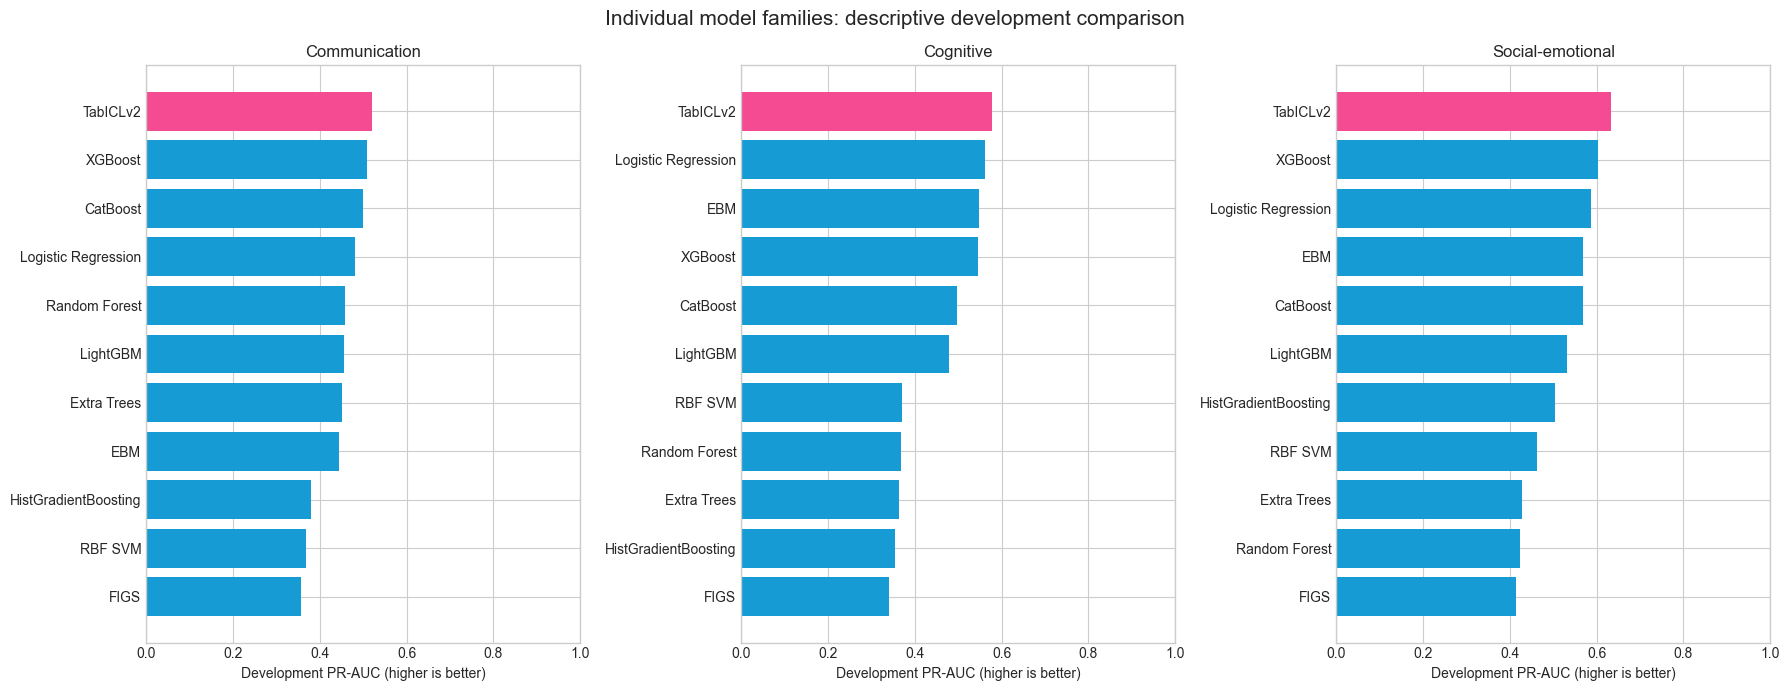

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7), sharex=True)
for ax, domain in zip(axes, DOMAINS.values()):
    view = development[development['Domain'] == domain].sort_values('PR-AUC')
    colors = ['#169BD5' if model != 'TabICLv2' else '#F44B93' for model in view['Model']]
    ax.barh(view['Model'], view['PR-AUC'], color=colors)
    ax.set_title(domain)
    ax.set_xlabel('Development PR-AUC (higher is better)')
    ax.set_xlim(0, 1)
fig.suptitle('Individual model families: descriptive development comparison', fontsize=15)
fig.tight_layout()
plt.show()

**Caution:** PR-AUC rank is a descriptive ordering of point estimates, not a statistical claim. Balanced accuracy and sensitivity remain key supporting operating metrics. Some later isolated reports do not contain aligned participant-level predictions against every earlier candidate, so a universal paired significance test cannot be reconstructed from aggregate reports.

## 3. Development comparison of Logistic–XGBoost hybrids

This experiment compares both component models, equal-weight soft voting and nested-CV selected-weight soft voting on identical outer observations. It is evaluated separately from the individual-family table to preserve the experiment boundary.

In [5]:
hybrid_report = load_report('development-hybrid-model-comparison-report.json')
hybrid_names = {
    'logistic_l2_balanced': 'Logistic Regression',
    'xgboost_regularized_balanced': 'XGBoost',
    'equal_weight_soft_voting': 'Equal-weight Logistic–XGBoost',
    'selected_weight_soft_voting': 'Selected-weight Logistic–XGBoost',
}
hybrid_rows, hybrid_ci_rows = [], []
for target, domain in DOMAINS.items():
    result = hybrid_report['domains'][target]
    for key, method in result['methods'].items():
        metrics = method['averaged_oof_metrics']
        hybrid_rows.append({'Domain': domain, 'Method': hybrid_names[key], **{m: metrics[m] for m in METRICS}})
    uncertainty = result['paired_uncertainty_selected_hybrid_vs_existing_reference']['differences']
    for metric, values in uncertainty.items():
        hybrid_ci_rows.append({'Domain': domain, 'Contrast': 'Selected-weight hybrid minus existing selected model', 'Metric': DISPLAY_METRICS.get(metric, metric), 'Mean difference': values['mean'], 'CI lower': values['confidence_interval_95'][0], 'CI upper': values['confidence_interval_95'][1]})

hybrid_development = pd.DataFrame(hybrid_rows).rename(columns=DISPLAY_METRICS)
hybrid_development['PR-AUC rank'] = hybrid_development.groupby('Domain')['PR-AUC'].rank(method='min', ascending=False).astype(int)
hybrid_development = hybrid_development.sort_values(['Domain', 'PR-AUC rank', 'Method'])
hybrid_columns = ['PR-AUC rank', 'Method', 'PR-AUC', 'Balanced accuracy', 'Sensitivity', 'Specificity', 'ROC-AUC', 'Precision', 'F1', 'Brier score']
for domain in DOMAINS.values():
    display(Markdown(f'### {domain}'))
    table = hybrid_development.loc[hybrid_development['Domain'] == domain, hybrid_columns]
    display(table.round(3).style.hide(axis='index').format({metric: '{:.3f}' for metric in DISPLAY_METRICS.values()}))
display(Markdown('### Paired uncertainty for the selected-weight hybrid'))
display(pd.DataFrame(hybrid_ci_rows).round(3).style.hide(axis='index'))

### Communication

PR-AUC rank,Method,PR-AUC,Balanced accuracy,Sensitivity,Specificity,ROC-AUC,Precision,F1,Brier score
1,Equal-weight Logistic–XGBoost,0.512,0.777,0.869,0.686,0.867,0.277,0.421,0.080
2,Selected-weight Logistic–XGBoost,0.506,0.748,0.820,0.677,0.860,0.260,0.395,0.080
3,XGBoost,0.503,0.727,0.705,0.749,0.847,0.281,0.402,0.080
4,Logistic Regression,0.480,0.812,0.934,0.690,0.874,0.295,0.449,0.082


### Cognitive

PR-AUC rank,Method,PR-AUC,Balanced accuracy,Sensitivity,Specificity,ROC-AUC,Precision,F1,Brier score
1,Logistic Regression,0.566,0.829,0.925,0.734,0.890,0.292,0.443,0.066
2,Selected-weight Logistic–XGBoost,0.561,0.840,0.906,0.774,0.895,0.322,0.475,0.065
3,Equal-weight Logistic–XGBoost,0.559,0.825,0.887,0.763,0.895,0.307,0.456,0.065
4,XGBoost,0.532,0.836,0.925,0.747,0.888,0.302,0.456,0.067


### Social-emotional

PR-AUC rank,Method,PR-AUC,Balanced accuracy,Sensitivity,Specificity,ROC-AUC,Precision,F1,Brier score
1,Equal-weight Logistic–XGBoost,0.603,0.812,0.814,0.810,0.892,0.364,0.503,0.069
2,XGBoost,0.602,0.808,0.763,0.853,0.885,0.409,0.533,0.069
3,Selected-weight Logistic–XGBoost,0.601,0.823,0.814,0.832,0.891,0.393,0.530,0.069
4,Logistic Regression,0.585,0.760,0.746,0.773,0.883,0.306,0.433,0.072


### Paired uncertainty for the selected-weight hybrid

Domain,Contrast,Metric,Mean difference,CI lower,CI upper
Communication,Selected-weight hybrid minus existing selected model,PR-AUC,0.003000,-0.028000,0.034000
Communication,Selected-weight hybrid minus existing selected model,Brier score,-0.000000,-0.002000,0.002000
Cognitive,Selected-weight hybrid minus existing selected model,PR-AUC,0.001000,-0.033000,0.034000
Cognitive,Selected-weight hybrid minus existing selected model,Brier score,-0.000000,-0.003000,0.002000
Social-emotional,Selected-weight hybrid minus existing selected model,PR-AUC,-0.000000,-0.027000,0.028000
Social-emotional,Selected-weight hybrid minus existing selected model,Brier score,0.000000,-0.002000,0.002000


## 4. Original locked-test evaluation of the initially selected models

This section reports the one-time evaluation of the frozen domain-specific models on the originally untouched 125-participant test cohort. Each domain had one previously selected model, so these rows document the original evidence rather than form a within-domain model ranking.

In [6]:
locked_report = load_report('final-locked-test-report.json')
locked_rows = []
for target, domain in DOMAINS.items():
    result = locked_report['domains'][target]
    version = result['model_configuration_version'].lower()
    model = 'XGBoost' if 'xgboost' in version else 'Logistic Regression'
    metrics = result['metrics']
    locked_rows.append({'Domain': domain, 'Model': model, **{m: metrics[m] for m in METRICS}})
locked_test = pd.DataFrame(locked_rows).rename(columns=DISPLAY_METRICS)
locked_columns = ['Domain', 'Model', 'PR-AUC', 'Balanced accuracy', 'Sensitivity', 'Specificity', 'ROC-AUC', 'Precision', 'F1', 'Brier score']
display(locked_test[locked_columns].round(3).style.hide(axis='index').format({metric: '{:.3f}' for metric in DISPLAY_METRICS.values()}))

Domain,Model,PR-AUC,Balanced accuracy,Sensitivity,Specificity,ROC-AUC,Precision,F1,Brier score
Communication,XGBoost,0.741,0.826,0.933,0.718,0.937,0.311,0.467,0.059
Cognitive,Logistic Regression,0.735,0.807,0.857,0.757,0.914,0.308,0.453,0.055
Social-emotional,XGBoost,0.489,0.758,0.733,0.782,0.852,0.314,0.440,0.083


## 5. Comparative evaluation on the common secondary cohort

The previously selected individual model, equal-weight Logistic–XGBoost hybrid, and TabICLv2 were evaluated on the same 125 participants. Within each domain, rows are ordered from highest to lowest **PR-AUC**, the declared primary metric for these imbalanced outcomes. Balanced accuracy is placed immediately beside PR-AUC, while sensitivity and the remaining metrics retain the operating-performance context.

This remains **secondary exploratory evidence**, not a fresh independent test, because the cohort had already been evaluated before the later methods were assessed. TabICLv2 is therefore labelled as a later experimental candidate, not a conclusively superior final model.

In [7]:
secondary_hybrid = load_report('secondary-exploratory-hybrid-evaluation-report.json')
secondary_tabicl = load_report('secondary-tabiclv2-test-evaluation-report.json')
secondary_rows = []
for target, domain in DOMAINS.items():
    h = secondary_hybrid['domains'][target]
    t = secondary_tabicl['domains'][target]
    original_version = h['original_individual']['model_configuration_version'].lower()
    original_name = 'XGBoost' if 'xgboost' in original_version else 'Logistic Regression'
    methods = [
        ('Initially selected', original_name, h['original_individual']['metrics']),
        ('Hybrid candidate', 'Equal-weight Logistic–XGBoost', h['equal_weight_hybrid']['metrics']),
        ('Later experimental candidate', 'TabICLv2', t['tabiclv2']['metrics']),
    ]
    for stage, model, metrics in methods:
        secondary_rows.append({
            'Domain': domain, 'Model stage': stage, 'Model': model,
            **{DISPLAY_METRICS[m]: metrics[m] for m in METRICS},
            'Evidence status': 'Secondary exploratory — reused cohort',
        })
secondary = pd.DataFrame(secondary_rows)
secondary['PR-AUC rank'] = secondary.groupby('Domain')['PR-AUC'].rank(method='min', ascending=False).astype(int)
secondary = secondary.sort_values(['Domain', 'PR-AUC rank', 'Model'])
comparison_columns = ['PR-AUC rank', 'Model stage', 'Model', 'PR-AUC', 'Balanced accuracy', 'Sensitivity', 'Specificity', 'ROC-AUC', 'Precision', 'F1', 'Brier score', 'Evidence status']
for domain in DOMAINS.values():
    display(Markdown(f'### {domain}'))
    table = secondary.loc[secondary['Domain'] == domain, comparison_columns]
    display(table.round(3).style.hide(axis='index').format({metric: '{:.3f}' for metric in DISPLAY_METRICS.values()}))

### Communication

PR-AUC rank,Model stage,Model,PR-AUC,Balanced accuracy,Sensitivity,Specificity,ROC-AUC,Precision,F1,Brier score,Evidence status
1,Later experimental candidate,TabICLv2,0.779,0.821,0.733,0.909,0.952,0.524,0.611,0.054,Secondary exploratory — reused cohort
2,Initially selected,XGBoost,0.741,0.826,0.933,0.718,0.937,0.311,0.467,0.059,Secondary exploratory — reused cohort
3,Hybrid candidate,Equal-weight Logistic–XGBoost,0.715,0.864,1.000,0.727,0.943,0.333,0.500,0.059,Secondary exploratory — reused cohort


### Cognitive

PR-AUC rank,Model stage,Model,PR-AUC,Balanced accuracy,Sensitivity,Specificity,ROC-AUC,Precision,F1,Brier score,Evidence status
1,Later experimental candidate,TabICLv2,0.781,0.812,0.786,0.838,0.909,0.379,0.512,0.051,Secondary exploratory — reused cohort
2,Hybrid candidate,Equal-weight Logistic–XGBoost,0.763,0.793,0.857,0.730,0.914,0.286,0.429,0.056,Secondary exploratory — reused cohort
3,Initially selected,Logistic Regression,0.735,0.807,0.857,0.757,0.914,0.308,0.453,0.055,Secondary exploratory — reused cohort


### Social-emotional

PR-AUC rank,Model stage,Model,PR-AUC,Balanced accuracy,Sensitivity,Specificity,ROC-AUC,Precision,F1,Brier score,Evidence status
1,Later experimental candidate,TabICLv2,0.520,0.780,0.733,0.827,0.867,0.367,0.489,0.081,Secondary exploratory — reused cohort
2,Hybrid candidate,Equal-weight Logistic–XGBoost,0.506,0.776,0.733,0.818,0.868,0.355,0.478,0.080,Secondary exploratory — reused cohort
3,Initially selected,XGBoost,0.489,0.758,0.733,0.782,0.852,0.314,0.440,0.083,Secondary exploratory — reused cohort


In [8]:
secondary_ci = []
for target, domain in DOMAINS.items():
    h = secondary_hybrid['domains'][target]
    t = secondary_tabicl['domains'][target]
    for metric in ['average_precision_pr_auc', 'balanced_accuracy', 'sensitivity']:
        h_ci = h['paired_uncertainty']['hybrid_minus_original_95_percentile_intervals'][metric]
        t_ci = t['paired_uncertainty']['tabiclv2_minus_original_95_percentile_intervals'][metric]
        secondary_ci.extend([
            {'Domain': domain, 'Contrast': 'Equal hybrid minus original', 'Metric': DISPLAY_METRICS[metric], 'Point difference': h['hybrid_minus_original_metric_differences'][metric], 'CI lower': h_ci['lower_95_percentile'], 'CI upper': h_ci['upper_95_percentile']},
            {'Domain': domain, 'Contrast': 'TabICLv2 minus original', 'Metric': DISPLAY_METRICS[metric], 'Point difference': t['tabiclv2_minus_original_metric_differences'][metric], 'CI lower': t_ci['lower'], 'CI upper': t_ci['upper']},
        ])
secondary_uncertainty = pd.DataFrame(secondary_ci)
display(Markdown('### Paired differences versus the initially selected model'))
display(secondary_uncertainty.round(3).style.hide(axis='index').format({'Point difference': '{:+.3f}', 'CI lower': '{:+.3f}', 'CI upper': '{:+.3f}'}))
display(Markdown('A 95% interval containing zero does not provide reliable evidence of a difference for that metric. There is no stored direct paired interval for TabICLv2 versus the hybrid.'))

### Paired differences versus the initially selected model

Domain,Contrast,Metric,Point difference,CI lower,CI upper
Communication,Equal hybrid minus original,PR-AUC,-0.027,-0.138,+0.069
Communication,TabICLv2 minus original,PR-AUC,+0.038,-0.032,+0.117
Communication,Equal hybrid minus original,Balanced accuracy,+0.038,-0.018,+0.118
Communication,TabICLv2 minus original,Balanced accuracy,-0.005,-0.115,+0.098
Communication,Equal hybrid minus original,Sensitivity,+0.067,+0.000,+0.200
Communication,TabICLv2 minus original,Sensitivity,-0.200,-0.400,+0.000
Cognitive,Equal hybrid minus original,PR-AUC,+0.028,-0.042,+0.110
Cognitive,TabICLv2 minus original,PR-AUC,+0.046,-0.061,+0.172
Cognitive,Equal hybrid minus original,Balanced accuracy,-0.014,-0.036,+0.009
Cognitive,TabICLv2 minus original,Balanced accuracy,+0.005,-0.076,+0.063


A 95% interval containing zero does not provide reliable evidence of a difference for that metric. There is no stored direct paired interval for TabICLv2 versus the hybrid.

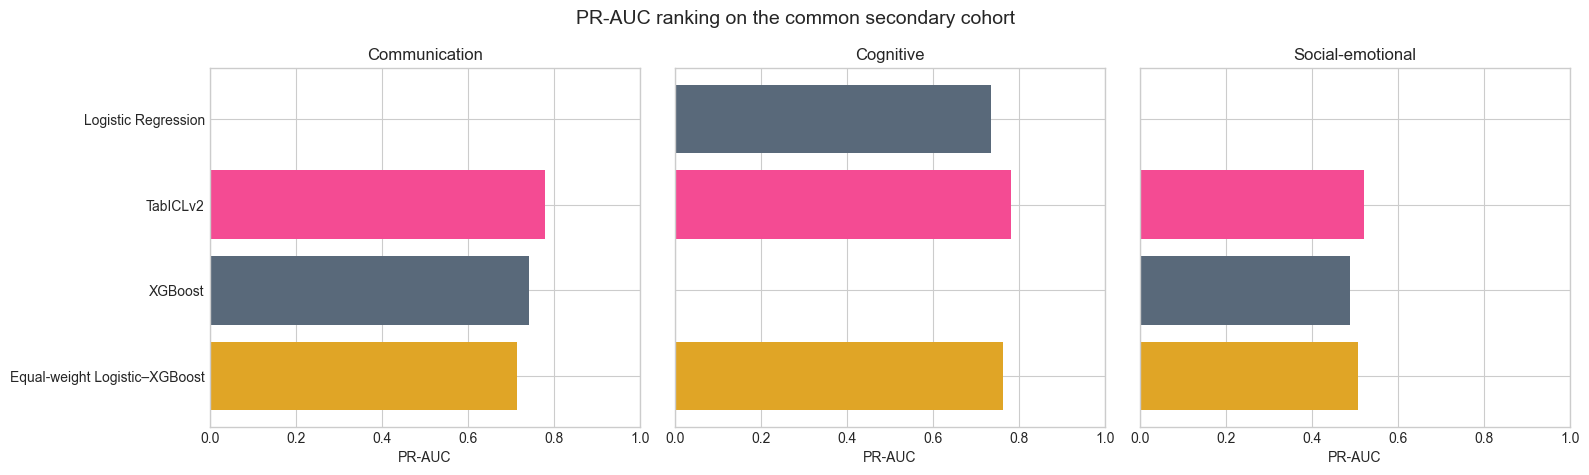

### Domain-by-domain justification

**Communication.** Highest PR-AUC: **TabICLv2** (0.779). Highest balanced accuracy: **Equal-weight Logistic–XGBoost** (0.864). Highest sensitivity: **Equal-weight Logistic–XGBoost** (1.000).

**Cognitive.** Highest PR-AUC: **TabICLv2** (0.781). Highest balanced accuracy: **TabICLv2** (0.812). Highest sensitivity: **Equal-weight Logistic–XGBoost, Logistic Regression** (0.857).

**Social-emotional.** Highest PR-AUC: **TabICLv2** (0.520). Highest balanced accuracy: **TabICLv2** (0.780). Highest sensitivity: **TabICLv2, Equal-weight Logistic–XGBoost, XGBoost** (0.733).

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, domain in zip(axes, DOMAINS.values()):
    view = secondary[secondary['Domain'] == domain].sort_values('PR-AUC', ascending=True)
    color_map = {'Initially selected': '#59697A', 'Hybrid candidate': '#E0A526', 'Later experimental candidate': '#F44B93'}
    ax.barh(view['Model'], view['PR-AUC'], color=[color_map[s] for s in view['Model stage']])
    ax.set_title(domain)
    ax.set_xlim(0, 1)
    ax.set_xlabel('PR-AUC')
fig.suptitle('PR-AUC ranking on the common secondary cohort', fontsize=14)
fig.tight_layout()
plt.show()

display(Markdown('### Domain-by-domain justification'))
for domain in DOMAINS.values():
    view = secondary[secondary['Domain'] == domain]
    best_ba = view.loc[view['Balanced accuracy'].idxmax()]
    best_ap = view.loc[view['PR-AUC'].idxmax()]
    max_sens = view['Sensitivity'].max()
    sensitivity_leaders = ', '.join(view.loc[np.isclose(view['Sensitivity'], max_sens), 'Model'])
    display(Markdown(
        f"**{domain}.** Highest PR-AUC: **{best_ap['Model']}** ({best_ap['PR-AUC']:.3f}). "
        f"Highest balanced accuracy: **{best_ba['Model']}** ({best_ba['Balanced accuracy']:.3f}). "
        f"Highest sensitivity: **{sensitivity_leaders}** ({max_sens:.3f})."
    ))

## 6. Evidence synthesis

A model should not be called better merely because it has the highest value in one table. A defensible conclusion should consider:

- development PR-AUC and its repeat stability;
- the sensitivity–specificity trade-off at the frozen domain threshold;
- probability quality through Brier score and calibration evidence;
- paired uncertainty when it is available;
- consistency across domains rather than extrapolation from one domain;
- whether the evidence is development, original locked-test, secondary exploratory, or external validation; and
- implementation, explainability and governance constraints.

The most supportable wording is therefore **metric- and domain-specific**: for example, a method may have a higher PR-AUC point estimate for one domain while another has higher sensitivity. TabICLv2 and the hybrids remain exploratory unless supported by new untouched or external validation.

### Evidence-based interpretation

> On the common 125-participant secondary cohort, TabICLv2 produced the highest PR-AUC point estimate in all three domains. Balanced-accuracy results were mixed: the equal-weight hybrid ranked first for Communication, whereas TabICLv2 ranked first for Cognitive and Social-emotional development. Sensitivity also showed domain-specific trade-offs. Paired uncertainty generally did not establish reliable overall superiority, and the cohort was previously evaluated. These findings support TabICLv2 as a promising later experimental candidate, not as a conclusively superior or independently validated final model.

## 7. Reporting limitations

1. The development cohort contains 500 participants, with relatively few positive outcomes per domain.
2. Repeated cross-validation estimates are correlated because the same participants appear across repeats.
3. Later isolated candidate reports do not provide every possible participant-aligned pairwise comparison.
4. The 125-participant cohort was previously examined; later hybrid and TabICLv2 evaluations on it are secondary and exploratory.
5. No external validation is represented here. Generalisability to other populations or settings is unestablished.
6. Multiple models, domains and metrics were inspected; apparent differences may reflect sampling variation.
7. These models estimate research outcomes defined from later domain scores. They do not diagnose developmental conditions.
8. The notebook summarizes stored evidence and deliberately does not recompute analyses from sensitive participant-level data.